# Bayesian Networks and Decision Analysis for Manufacturing Quality

Probabilistic reasoning on a 3D-printing quality scenario: descriptive statistics and regression on process data, Bayes-rule calculations for a quality-assurance protocol, a Bayesian network and an influence diagram in **pyAgrum**, expected-value decisions about keeping QA and paying for better process control or information, and a Simpson's-paradox case on treatment effectiveness.


# 1

## Scenario 1

FastMade is a London-based 3D-printing company that provides custom-made parts to other 
businesses. On one order, they print several samples. For each sample, they observe the flow rate 
and the temperature of their feedstock during printing. They measure how robust the resulting 
structure is. The measurements can be found in the attached .csv file. 
<br>
a) Load the CSV in python. Compute the mean and standard deviation for the printing 
temperature. 

In [99]:
import pandas as pd

# csv load
data = pd.read_csv('data/3d_printing.csv')

Mean = (1/n) * Σ (xᵢ)

Where:
- n = number of observations
- xᵢ = each individual observation

Standard Deviation = √( (1/n) * Σ (xᵢ - x̄)² )

Where:
- n = number of observations
- xᵢ = each individual observation
- x̄ = mean of the observations

In [ ]:
# mean
mean_temperature = data['Temperature'].mean()
# std
std_temperature = data['Temperature'].std()

#printing
print("Mean Printing Temperature:", mean_temperature)
print("Standard Deviation:", std_temperature)

Mean Printing Temperature: 210.96666666666667
Standard Deviation: 16.80205926076619


### Basic Data Quality Checking

In [101]:
from ydata_profiling import ProfileReport

In [102]:
ProfileReport(data, title="Profiling Report")

### There is no problem so moving on.

b) Separate the temperature into three categories: low (less than 200 degrees), medium (200-220 
degrees, both inclusive), and high (more than 220 degrees). Compute the frequency of each 
category, then use these frequencies to compute the probability table for 
P(TemperatureCategory).

- **Low:** Temperature < 200°C
- **Medium:** 200°C ≤ Temperature ≤ 220°C
- **High:** Temperature > 220°C

In [103]:
# function to categorize temperature
def categorize_temperature(temp):
    if temp < 200:
        return 'low'
    elif 200 <= temp <= 220:
        return 'medium'
    else:
        return 'high'

# apply the func and categorize the temp
data['TempCategory'] = data['Temperature'].apply(categorize_temperature)

# computing the frequencies
frequency = data['TempCategory'].value_counts().sort_index()
print("Frequency of Temperature Categories:")
print(frequency)

Frequency of Temperature Categories:
TempCategory
high       8
low       10
medium    12
Name: count, dtype: int64


### Probability table for P(TemperatureCategory)

In [104]:
total = frequency.sum()
probability_table = frequency / total
# reordering categories
probability_table = probability_table.reindex(['low', 'medium', 'high'])
print("Probability Table P(TemperatureCategory):")
print(probability_table)

Probability Table P(TemperatureCategory):
TempCategory
low       0.333333
medium    0.400000
high      0.266667
Name: count, dtype: float64


c) In Python, use linear regression to predict the robustness given the temperature category and 
the flow rate. Report the intercept, coefficients, and mean squared error for your model. 

In [105]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split


# creating dummy data fpr TempCategory and dropping low as it is the first one
data = pd.get_dummies(data, columns=['TempCategory'], drop_first=True)

# mapping the categorical column Robustness to numeric values, 0 for weak, 1 for moderate, 2 for stong
robustness_mapping = {'weak': 0, 'moderate': 1, 'strong': 2}
data['Robustness_numeric'] = data['Robustness'].str.lower().map(robustness_mapping)

# mapping the categorical column flowrate to numeric values, 0 for low, 1 for high
flowrate_mapping = {'low': 0, 'high': 1}
data['FlowRate_numeric'] = data['FlowRate'].str.lower().map(flowrate_mapping)

# filtering only the predictors
X = data[['FlowRate_numeric', 'TempCategory_low', 'TempCategory_medium']]
# filtering only the predictee
y = data['Robustness_numeric'].astype(int)

# train test splitting - 80/20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# model initialization
model = LinearRegression()
# model fitting
model.fit(X_train, y_train)

# predict on the test set
y_pred = model.predict(X_test)

# intercept
intercept = model.intercept_
# coefficient
coefficients = model.coef_
#mse
mse = mean_squared_error(y_test, y_pred)

### Results

In [106]:
print("Linear Regression Model Results:")
print("Intercept:", intercept)
print("Coefficients:", coefficients)
print("Mean Squared Error:", mse)

Linear Regression Model Results:
Intercept: 1.9663222349789509
Coefficients: [-0.59931114 -1.5093762  -0.33027172]
Mean Squared Error: 0.16576876478002325


We have MSE of 0.1657 which is less than 0.2. So, we can say that our model is good.

# 2

## Scenario 2
Lisa is using parts from FastMade for her company. Because she knows the parts are of varying 
robustness, she uses a quality assurance (QA) protocol. When she receives a part, she double
checks the robustness. If a part doesn't pass QA, she discards it. Weakly robust parts pass QA 
30% of the time; moderately robust parts pass QA 60% of the time; and strongly robust parts 
pass QA 90% of the time. 
1 
Her goal is to minimise how often her products break. If not discarded, her products break 50% 
of the time with a weakly robust part, 10% of the time with a moderately robust part, and 1% of 
the time with a strongly robust part.


a) Using the FastMade dataset, Lisa computes the probability of a high flowrate. She does so 
simply by counting the ratio of samples with a high flowrate to all samples. She gets P(FlowRate) 
= 0.5. Use python to double-check her work.

In [107]:
# count of how many samples have high flow rate
high_flow_count = data[data['FlowRate'] == 'High'].shape[0]
# calculate the probability of samples with high flow rate
p_high_flow = high_flow_count / len(data)
#printing the prob of high flowrate
print("Probability of High FlowRate (categorical):", p_high_flow)

Probability of High FlowRate (categorical): 0.5


b) Based on the frequencies in the provided dataset from the previous exercise, compute 
P(Robustness) and P(Robustness | Temperature, FlowRate). You can do so either by hand, or 
using python. 

### Computing P(Robustness)

In [108]:
# calculate the relative frequency of each Robustness category
robustness_probs = data['Robustness'].value_counts(normalize=True)
print("P(Robustness):")
print(robustness_probs)


P(Robustness):
Robustness
Moderate    0.366667
Strong      0.366667
Weak        0.266667
Name: proportion, dtype: float64


### Computing P(Robustness | Temperature, FlowRate)

In [ ]:
# since we applied one hot encoding above, recreating TempCategory again. Also for reproducibility adding a control just in case for rerunning the code
if 'TempCategory' not in data.columns:
    data['TempCategory'] = data['Temperature'].apply(categorize_temperature)

# computing conditional probabilities by grouping by Temperature category and FlowRate, better for plotting the table since it is more organised this way


# calculating the relative frequency of each Robustness level for each combination.
conditional_probs = data.groupby(['TempCategory', 'FlowRate'])['Robustness'].value_counts(normalize=True).rename("P(Robustness|Temperature,FlowRate)")

print("\nP(Robustness | Temperature, FlowRate):")
print(conditional_probs)


P(Robustness | Temperature, FlowRate):
TempCategory  FlowRate  Robustness
high          High      Strong        0.600000
                        Moderate      0.400000
              Low       Strong        1.000000
low           High      Weak          1.000000
              Low       Weak          0.600000
                        Moderate      0.400000
medium        High      Moderate      1.000000
              Low       Strong        0.714286
                        Moderate      0.285714
Name: P(Robustness|Temperature,FlowRate), dtype: float64


c) Compute P(Breaks | PassesQA). You can do so either by hand, or using python.

In [ ]:
# defining QA break and no break
PassesQA = {"weak": 0.3, "moderate": 0.6, "strong": 0.9}
Breaks = {"weak": 0.5, "moderate": 0.1, "strong": 0.01}

$P(PassesQA) = \sum_{i}{P(PassesQA|Robustness_i) * P(Robustness_i)}$

In [ ]:
# robustness to lowercase
data['Robustness'] = data['Robustness'].str.lower()

# P(PassesQA)
passes = 0
robustness_probs = data['Robustness'].value_counts(normalize=True)

for robustness in robustness_probs.index:
    passes += robustness_probs.loc[robustness] * PassesQA[robustness]
    
print(f"P(PassesQA) = {passes}")

P(PassesQA) = 0.6299999999999999


$P(Robustness∣PassesQA) = \frac{P(PassesQA|Robustness_i) * P(Robustness_i)}{P(PassesQA)}$

In [112]:
# calculating P(Robustness∣PassesQA)
given_passes = {}
for robustness in robustness_probs.index:
    given_passes[robustness] = (robustness_probs.loc[robustness] * PassesQA[robustness]) / passes

print(f"P(Robustness | PassesQA) = {given_passes}")

P(Robustness | PassesQA) = {'moderate': 0.34920634920634924, 'strong': 0.5238095238095238, 'weak': 0.126984126984127}


$P(Breaks|PassesQA) = \sum_{i}{P(Breaks|Robustness_i) * P(Robustness_i|PassesQA)}$

In [113]:
# calculating P(Breaks | PassesQA)
P_break_given_pass = 0
for robustness in robustness_probs.index:
    P_break_given_pass += given_passes[robustness] * Breaks[robustness]

print(f"P(Breaks | PassesQA) = {P_break_given_pass}")


P(Breaks | PassesQA) = 0.10365079365079366


d) Compute P(Weak | Breaks, PassesQA). You can do so either by hand, or using python.

$P(Breaks,PassesQA) = P(Breaks|PassesQA) * P(PassesQA)$

In [114]:
# P(Breaks, PassesQA) = P(Breaks | PassesQA) * P(PassesQA)
breaks_and_passes = P_break_given_pass * passes
print(f"P(Breaks, PassesQA) = {breaks_and_passes:.6f}")

P(Breaks, PassesQA) = 0.065300


In [143]:
print("DEBUG CHECK:")
print("Robustness Probs:", robustness_probs.to_dict())
print("P(PassesQA):", passes)
print("given_passes:", given_passes)
print("Breaks:", Breaks)
print(f"P(Breaks | PassesQA): {P_break_given_pass:.6f}")


DEBUG CHECK:
Robustness Probs: {'moderate': 0.36666666666666664, 'strong': 0.36666666666666664, 'weak': 0.26666666666666666}
P(PassesQA): 0.6299999999999999
given_passes: {'moderate': 0.34920634920634924, 'strong': 0.5238095238095238, 'weak': 0.126984126984127}
Breaks: {'weak': 0.5, 'moderate': 0.1, 'strong': 0.01}
P(Breaks | PassesQA): 0.103651


$P(Weak|Breaks,PassesQA) = \frac{P(Breaks|Weak) * P(Weak|PassesQA)}{P(Breaks|PassesQA)}$

In [116]:
# P(Weak | Breaks, PassesQA)
data['Robustness'] = data['Robustness'].str.lower()
P_weak_given_breaks_and_passes = (Breaks["weak"] * given_passes["weak"]) / P_break_given_pass

print(f"P(Weak | Breaks, PassesQA) = {P_weak_given_breaks_and_passes:.6f}")

P(Weak | Breaks, PassesQA) = 0.612557


# 3

## Scenario 3
Lisa's scenario -- FastMade's temperature category and flowrate influencing robustness, a QA 
process that discards samples based on robustness, and breakage for the kept samples -- can be 
expressed as a Bayesian network with 5 nodes: 

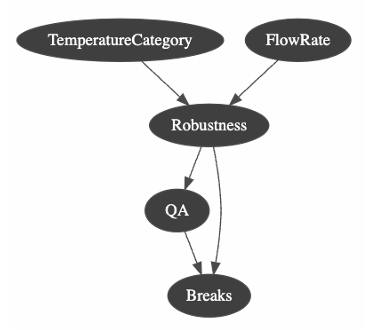

<br>
a) Implement the Bayesian network in PyAgrum, and compute the marginal probability that a 
product breaks. 

In [ ]:
import pyAgrum as gum
import pyAgrum.lib.notebook as gnb
bn = gum.BayesNet()

In [ ]:
import pyAgrum as gum

# initializing BayesNet
bn = gum.BayesNet('FastMadeBN')

# adding the nodes
bn.add(gum.LabelizedVariable('Temperature', 'Temperature Category', ['Low','Medium','High']))
bn.add(gum.LabelizedVariable('FlowRate', 'Material Flow Rate', ['Low','High']))
bn.add(gum.LabelizedVariable('Robustness', 'Part Robustness', ['Weak','Moderate','Strong']))
bn.add(gum.LabelizedVariable('PassesQA', 'QA Outcome', ['Fail','Pass']))
bn.add(gum.LabelizedVariable('Breaks', 'Product Breaks', ['No','Yes']))

# arcs
bn.addArc('Temperature', 'Robustness')
bn.addArc('FlowRate', 'Robustness')
bn.addArc('Robustness', 'PassesQA')
bn.addArc('Robustness', 'Breaks')
bn.addArc('PassesQA', 'Breaks')

# cpt for temperature
bn.cpt('Temperature').fillWith([0.3333, 0.4, 0.2667])

# cpt for flowrate
bn.cpt('FlowRate').fillWith([0.5, 0.5])

# cpt for robustness given parents Temperature and Flowrate 
bn.cpt('Robustness')[{'Temperature': 'Low', 'FlowRate': 'Low'}]    = [0.6, 0.4, 0.0]
bn.cpt('Robustness')[{'Temperature': 'Low', 'FlowRate': 'High'}]   = [1.0, 0.0, 0.0]
bn.cpt('Robustness')[{'Temperature': 'Medium','FlowRate': 'Low'}]  = [0.0, 0.2857, 0.7143]
bn.cpt('Robustness')[{'Temperature': 'Medium','FlowRate': 'High'}] = [0.0, 1.0,   0.0]
bn.cpt('Robustness')[{'Temperature': 'High','FlowRate': 'Low'}]    = [0.0, 0.0,   1.0]
bn.cpt('Robustness')[{'Temperature': 'High','FlowRate': 'High'}]   = [0.0, 0.4,   0.6]

# cpt for passesqa given Robustness
bn.cpt('PassesQA')[{'Robustness': 'Weak'}]     = [0.7, 0.3] 
bn.cpt('PassesQA')[{'Robustness': 'Moderate'}] = [0.4, 0.6]   
bn.cpt('PassesQA')[{'Robustness': 'Strong'}]   = [0.1, 0.9]   

# cpt for breaks given robustness and passesqa
# assuming since it's discarded it cannot break
bn.cpt('Breaks')[{'Robustness': 'Weak',    'PassesQA': 'Fail'}] = [1, 0]   
bn.cpt('Breaks')[{'Robustness': 'Weak',    'PassesQA': 'Pass'}] = [0.5, 0.5]  
bn.cpt('Breaks')[{'Robustness': 'Moderate','PassesQA': 'Fail'}] = [1, 0]  
bn.cpt('Breaks')[{'Robustness': 'Moderate','PassesQA': 'Pass'}] = [0.9, 0.1]   
bn.cpt('Breaks')[{'Robustness': 'Strong',  'PassesQA': 'Fail'}] = [1, 0]   
bn.cpt('Breaks')[{'Robustness': 'Strong',  'PassesQA': 'Pass'}] = [0.99, 0.01] 

# performing the inference
ie = gum.LazyPropagation(bn)
ie.makeInference()
# Breaks probability
p_breaks = ie.posterior("Breaks")[1]

import pyAgrum.lib.notebook as gnb

for var in bn.nodes():
    gnb.showPotential(bn.cpt(var))

print(f"Marginal Probability of a Product Breaking: {p_breaks:.4f}")

Marginal Probability of a Product Breaking: 0.0658


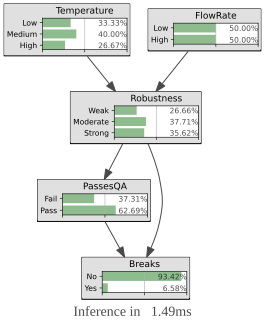

In [120]:
# Plot Bayesian network structure
gnb.showInference(bn)

The Bayesian network predicts that 6.58% of the products will break, considering temperature, flow rate, robustness, QA process, and break probabilities.

b) A product is made using a component produced with high flow rate. The product breaks. What 
is the probability that it was Strongly robust? 

In [ ]:
import pyAgrum as gum
import pyAgrum.lib.notebook as gnb

# inference
ie = gum.LazyPropagation(bn)
ie.setEvidence({'FlowRate': 'High', 'Breaks': 'Yes'})
ie.makeInference()
# computing the probability of robustness:Strong given the evidence
prob_strong_given_evidence = ie.posterior('Robustness')[2]

print(f"Probability that the component was Strongly Robust given high flow rate and the product breaks: {prob_strong_given_evidence:.4f}")

Probability that the component was Strongly Robust given high flow rate and the product breaks: 0.0176


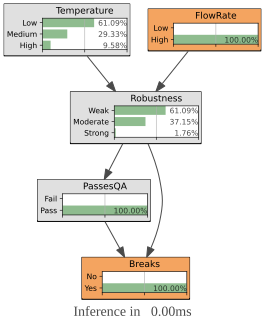

In [122]:
gnb.showInference(bn, evs={"FlowRate":"High","Breaks":"Yes"})

Given that a product with high flow rate has broken, the probability that it was Strongly Robust is only 1.76%. This indicates that breakages are more likely from weaker components.

c) What is the relative risk of products breaking if produced at low versus high temperature? 

Probability of breaking at Low Temperature: 0.1320
Probability of breaking at High Temperature: 0.0192
Relative Risk of breaking (Low vs High Temperature): 6.8750


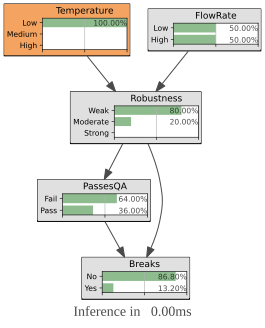

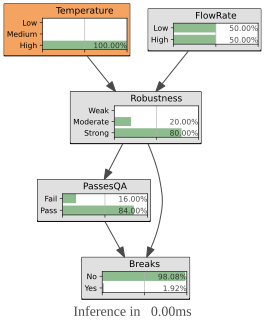

In [ ]:
import pyAgrum as gum
import pyAgrum.lib.notebook as gnb

# lazypropagation
ie = gum.LazyPropagation(bn)

# P(Breaks='Yes' | Temperature='Low')
ie.setEvidence({'Temperature': 'Low'})
ie.makeInference()
p_break_low_temp = ie.posterior('Breaks')[1]

# P(Breaks='Yes' | Temperature='High')
ie.setEvidence({'Temperature': 'High'})
ie.makeInference()
p_break_high_temp = ie.posterior('Breaks')[1]

# relative risk
relative_risk = p_break_low_temp / p_break_high_temp

print(f"Probability of breaking at Low Temperature: {p_break_low_temp:.4f}")
print(f"Probability of breaking at High Temperature: {p_break_high_temp:.4f}")
print(f"Relative Risk of breaking (Low vs High Temperature): {relative_risk:.4f}")

# the inference for both conditions
gnb.showInference(bn, evs={"Temperature":"Low"})
gnb.showInference(bn, evs={"Temperature":"High"})


The relative risk of a product breaking when produced at low temperature versus high temperature is 6.875. This means that low-temperature manufacturing significantly increases breakage likelihood.

## Scenario 4
Lisa is considering dropping the quality assurance process. If a product is not discarded, she can 
sell it for £2,000. However, if the product breaks, she may have to pay a compensation worth 
£10,000. 


a) Draw an influence diagram representing this situation in PyAgrum 

In [142]:
import pyAgrum as gum
import pyAgrum.lib.notebook as gnb

# creating the BayesNet
bn = gum.BayesNet('Lisa_FastMade')

# adding nodes
doQA = bn.add(gum.LabelizedVariable("DoQA", "Do Quality Assurance?", ['No', 'Yes']))
robustness = bn.add(gum.LabelizedVariable("Robustness", "Robustness", ['Weak', 'Moderate', 'Strong']))
passQA = bn.add(gum.LabelizedVariable("PassQA", "Passes QA", ['Fail', 'Pass']))
breaks = bn.add(gum.LabelizedVariable("Breaks", "Breakage", ['Doesn’t Break', 'Breaks']))

# arcs
bn.addArc(doQA, passQA)
bn.addArc(robustness, passQA)
bn.addArc(robustness, breaks)
bn.addArc(passQA, breaks)

# BayesNet properties
print(bn)

# BayesNet display
bn


BN{nodes: 4, arcs: 4, domainSize: 24, dim: 15, mem: 232o}


(pyAgrum.BayesNet@000002ABEFCEEAA0) BN{nodes: 4, arcs: 4, domainSize: 24, dim: 15, mem: 232o}

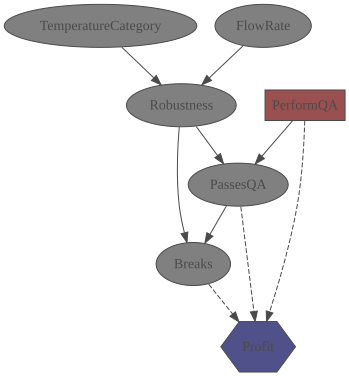

In [ ]:
import pyAgrum as gum
import pyAgrum.lib.notebook as gnb

# initializing the diagram
idg = gum.InfluenceDiagram()

# adding random variables
idg.add(gum.LabelizedVariable("TemperatureCategory", "Temperature Category", ["Low", "Medium", "High"]))
idg.add(gum.LabelizedVariable("FlowRate", "Material Flow Rate", ["Low", "High"]))
idg.add(gum.LabelizedVariable("Robustness", "Part Robustness", ["Weak", "Moderate", "Strong"]))
idg.add(gum.LabelizedVariable("PassesQA", "QA Outcome", ["Fail", "Pass"]))
idg.add(gum.LabelizedVariable("Breaks", "Product Breaks", ["No", "Yes"]))

# add decision node of QA
idg.addDecisionNode(gum.LabelizedVariable("PerformQA", "Perform QA?", ["Yes", "No"]))

# add utility node of profit
idg.addUtilityNode("Profit")

# arcs

# Temperature affects robustness
idg.addArc("TemperatureCategory", "Robustness")  
# FlowRate affects robustness
idg.addArc("FlowRate", "Robustness")   
# Robustness affects QA outcome         
idg.addArc("Robustness", "PassesQA") 
# Robustness affects break probability           
idg.addArc("Robustness", "Breaks")    
# QA influences break probability          
idg.addArc("PassesQA", "Breaks")  
# QA decision affects QA outcome              
idg.addArc("PerformQA", "PassesQA")           
# Breakage affects profit  
idg.addArc("Breaks", "Profit")                  



# indirect influence aka dashed line
# QA indirectly affects profit
idg.addArc("PerformQA", "Profit")  
# passing QA affects profit indirectly
idg.addArc("PassesQA", "Profit")   

# displaying the diagram
gnb.showInfluenceDiagram(idg)


b) Should Lisa keep the QA process? How much does she stand to make on average per product, 
if she does? 

In [ ]:
# defining probability distributions and financial metrics
robustness_dist = {"Weak": 0.267, "Moderate": 0.367, "Strong": 0.367}
failure_chance = {"Weak": 0.50, "Moderate": 0.10, "Strong": 0.01}
qa_pass_chance = {"Weak": 0.30, "Moderate": 0.60, "Strong": 0.90}
PRICE_PER_UNIT = 2000
LOSS_PER_FAILURE = 10000

# no QA applied and all products are sold
fail_prob_total = sum(robustness_dist[tier] * failure_chance[tier] for tier in robustness_dist)
profit_without_qa = PRICE_PER_UNIT - (fail_prob_total * LOSS_PER_FAILURE)

# QA applied and only passed ones are sold
prob_successful_qa = sum(robustness_dist[tier] * qa_pass_chance[tier] for tier in robustness_dist)
fail_prob_after_qa = sum(
    robustness_dist[tier] * qa_pass_chance[tier] * failure_chance[tier] for tier in robustness_dist
) / prob_successful_qa

profit_with_qa = (prob_successful_qa * PRICE_PER_UNIT) - (prob_successful_qa * fail_prob_after_qa * LOSS_PER_FAILURE)

# results
print(f"Revenue Estimate (No QA): £{profit_without_qa:.2f}")
print(f"Revenue Estimate (With QA): £{profit_with_qa:.2f}")


profit_diff = profit_with_qa - profit_without_qa

if profit_diff > 0:
    print(f"Keep QA. Extra profit per unit: £{profit_diff:.2f}")
else:
    print(f"Drop QA. Extra earnings per unit: £{abs(profit_diff):.2f} by skipping QA.")


Revenue Estimate (No QA): £261.30
Revenue Estimate (With QA): £607.47
Keep QA. Extra profit per unit: £346.17


Lisa should keep QA as it increases the profit.

c) After analysing their data, FastMade improves their control over the printing process. They 
ensure that all samples are printed at low flow rate, as this improves robustness. How much is this 
improvement worth to Lisa (per product)?

In [141]:
# new robustness probabilities after improvement
robustness_dist_new = {"Weak": 0.2, "Moderate": 0.2286, "Strong": 0.5714}

# a function to compute E[revenue]
def calculate_expected_revenue(robustness_distribution):
    pass_qa_prob = sum(robustness_distribution[tier] * qa_pass_chance[tier] for tier in robustness_distribution)
    fail_prob_after_qa = sum(
        robustness_distribution[tier] * qa_pass_chance[tier] * failure_chance[tier] 
        for tier in robustness_distribution
    ) / pass_qa_prob
    return (pass_qa_prob * PRICE_PER_UNIT) - (pass_qa_prob * fail_prob_after_qa * LOSS_PER_FAILURE)

# compute revenue before improvement
revenue_before = calculate_expected_revenue(robustness_dist)
# compute revenue after improvement
revenue_after = calculate_expected_revenue(robustness_dist_new)

# calculate the added value per unit
revenue_increase = revenue_after - revenue_before

#the results
print(f"Projected Revenue BEFORE Process Improvement: £{revenue_before:.2f}")
print(f"Projected Revenue AFTER Process Improvement: £{revenue_after:.2f}")
print(f"Added Value Per Unit: £{revenue_increase:.2f}")


Projected Revenue BEFORE Process Improvement: £607.47
Projected Revenue AFTER Process Improvement: £934.25
Added Value Per Unit: £326.78


FastMade's improvement in printing control significantly increases the profit

d) FastMade also offers Lisa to share their data on temperature category, allowing her to bypass 
QA selectively for products made at low, medium, or high temperatures. That is, she could decide 
to carry out QA only for products made at medium temperature – or high, low, or some 
combination of the three. Will she benefit from this? How much is sharing this information worth 
to Lisa (per product)? Assume all components are still produced using a low flow rate. 

In [ ]:
# temp related robustness probabilities
robustness_temp_low = {"Weak": 0.6, "Moderate": 0.4, "Strong": 0.0}
robustness_temp_medium = {"Weak": 0.0, "Moderate": 0.2857, "Strong": 0.7143}
robustness_temp_high = {"Weak": 0.0, "Moderate": 0.0, "Strong": 1.0}

# temp probabilities
temp_distribution = {"Low": 0.3333, "Medium": 0.4, "High": 0.2667}

# computing revenue before implementing selective QA
revenue_before_temp_data = calculate_expected_revenue(robustness_dist_new)

# computing revenue after selectively applying QA based on temperature
revenue_after_temp_data = (
    temp_distribution["Low"] * calculate_expected_revenue(robustness_temp_low) +  
    temp_distribution["Medium"] * calculate_expected_revenue(robustness_temp_medium) +  
    temp_distribution["High"] * PRICE_PER_UNIT  # High-temp: No QA needed, always strong, no breakage
)

# calculating the additional revenue gained per unit
value_of_temperature_data = revenue_after_temp_data - revenue_before_temp_data

#results
print(f"Projected Revenue BEFORE Temperature-Based QA: £{revenue_before_temp_data:.2f}")
print(f"Projected Revenue AFTER Temperature-Based QA: £{revenue_after_temp_data:.2f}")
print(f"Additional Revenue Per Unit from Temperature Data: £{value_of_temperature_data:.2f}")


Projected Revenue BEFORE Temperature-Based QA: £934.25
Projected Revenue AFTER Temperature-Based QA: £990.56
Additional Revenue Per Unit from Temperature Data: £56.31


Using temperature data to selectively apply QA increases expected revenue per unit

## Scenario 5
You are analysing the effectiveness of two drugs, A and B, used to treat a specific condition. 
Depending on how early the condition is diagnosed, doctors tend to choose a different drug. 
60% of cases are discovered early, and 40% are discovered late. When diagnosed early, patients 
are in 90% of cases given drug A; when diagnosed late, patients are given drug A 40% of the 
time. 


Recovery rates depend on discovery time, and on which drug was used. When diagnosed early 
and given drug A, 80% of patients recover. For early diagnosis and drug B, 90% recover. In the 
case of late diagnosis, 50% of patients recover with drug A, and 60% with drug B.

a) Draw a Bayesian network showing this situation in PyAgrum

In [129]:
import pyAgrum as gum
import pyAgrum.lib.notebook as gnb

# creating the BayesNet
bn = gum.BayesNet('DrugEffectiveness')

# adding the nodes for each var
bn.add(gum.LabelizedVariable('DiagnosisTime', 'Time of Diagnosis', ['Early', 'Late']))
bn.add(gum.LabelizedVariable('DrugChoice', 'Drug Administered', ['A', 'B']))
bn.add(gum.LabelizedVariable('Recovery', 'Patient Recovery', ['No', 'Yes']))

# conditional dependancies
# diagnosis time on drug choice
bn.addArc('DiagnosisTime', 'DrugChoice')  
# diagnosis time on recovery
bn.addArc('DiagnosisTime', 'Recovery')   
# choice of drug on recovery 
bn.addArc('DrugChoice', 'Recovery')       

# set cpt for diagnosistime, basically prior probabilities
# Early: 60% and Late: 40%
bn.cpt('DiagnosisTime').fillWith([0.6, 0.4])  

# cpt for drugchoice given diagnosistime
# Early: 90% A, 10% B
bn.cpt('DrugChoice')[{'DiagnosisTime': 'Early'}] = [0.9, 0.1]  
# Late: 40% A, 60% B
bn.cpt('DrugChoice')[{'DiagnosisTime': 'Late'}] = [0.4, 0.6]  

# cpt for recovery given diagnosistime and drugchoice
# 80% recover with A
bn.cpt('Recovery')[{'DiagnosisTime': 'Early', 'DrugChoice': 'A'}] = [0.2, 0.8]  
# 90% recover with B
bn.cpt('Recovery')[{'DiagnosisTime': 'Early', 'DrugChoice': 'B'}] = [0.1, 0.9]  
# 50% recover with A
bn.cpt('Recovery')[{'DiagnosisTime': 'Late', 'DrugChoice': 'A'}] = [0.5, 0.5]   
# 60% recover with B
bn.cpt('Recovery')[{'DiagnosisTime': 'Late', 'DrugChoice': 'B'}] = [0.4, 0.6]   

### Graph

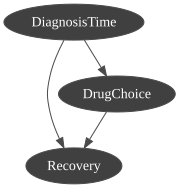

In [130]:
# showing the graph
gnb.showBN(bn)

### Inference Graph

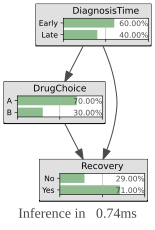

In [131]:
# showing the inference graph
gnb.showInference(bn)

b) What are the absolute risks of not recovering for each drug? 

In [132]:
# lazypropagation
ie = gum.LazyPropagation(bn)

# computing  P(Recovery='No' | DrugChoice='A')
ie.setEvidence({'DrugChoice': 'A'})
ie.makeInference()
# probability of no
p_no_recovery_A = ie.posterior('Recovery')[0]  

# computing P(Recovery='No' | DrugChoice='B')
ie.setEvidence({'DrugChoice': 'B'})
ie.makeInference()
# probability of no
p_no_recovery_B = ie.posterior('Recovery')[0]  

### Absolute Risks of not Recovering

In [133]:
# output
print(f"Absolute Risk of Not Recovering for Drug A: {p_no_recovery_A:.4f}")
print(f"Absolute Risk of Not Recovering for Drug B: {p_no_recovery_B:.4f}")

Absolute Risk of Not Recovering for Drug A: 0.2686
Absolute Risk of Not Recovering for Drug B: 0.3400


c) Based on this, a doctor concludes that drug A is more effective. Is he right? If not, why? What is 
the name of the phenomenon that mislead him?.

The doctor's claim is wrong based on Simpson's Paradox. At first, it looks like patients taking Drug A are more likely to recover, but that’s only because this drug is prescribed more often to people diagnosed early, who already have a higher chance of getting better. When we look closely at the early and late diagnoses, Drug B performs better in recovery rates.

This means that if there are two patients at the same stage of the illness, the one taking Drug B has a better chance at recovering than the one on Drug A. The Doctor's mistake comes from not considering the diagnosis timing affecting the data. Since Drug A is more commonly used in early cases, the overall numbers make it seem more effective, but that’s not actually true when we compare similar patients. In reality, Drug B is the better option.

#### **Early Diagnosis (60% of cases)**

- **Drug A:** **80%** recover, **20%** do not
- **Drug B:** **90%** recover, **10%** do not
#### **Late Diagnosis (40% of cases)**

- **Drug A:** **50%** recover, **50%** do not
- **Drug B:** **60%** recover, **40%** do not